# 07 - Exercise 2: metrics, score and pool
Brief (assumed): defensive midfielder, under 26, salary ≤ $1M, market value ≤ €7M, other MLS club, ≥ 1,200 minutes in 2026. 60% ball-winning, 40% progression.

1. Peer group and candidates
2. Metrics
3. Per-96 values
4. Percentiles
5. Score and sub-scores
6. Pool
7. Robustness checks
8. Chart
9. Save

## Setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

PROCESSED_FOLDER = Path("../../data/processed")
FIGURES_FOLDER = Path("../../figures")

# brief
MIN_MINUTES = 1200            # ~13 full matches
MAX_AGE = 26
MAX_SALARY = 1_000_000
MIN_BALL_WINNING = 50         # priority skill: above the league median
MIN_PROGRESSION = 45          # secondary skill: around the league median or better

# colours
POOL_COLOR = "#2a78d6"         # blue = shortlist pool
PEER_COLOR = "#c3c2b7"         # light grey = rest of the league
BACKGROUND = "#fcfcfb"
TEXT_COLOR = "#0b0b0b"
TEXT_MUTED = "#52514e"
GRID_COLOR = "#e4e3df"

In [2]:
mls_2026 = pd.read_parquet(PROCESSED_FOLDER / "asa_players_2026.parquet")
mls_2026.shape

(817, 50)

## 1 - Peer group and candidates
- Peer group: MLS central/defensive midfielders with ≥ 1,200 minutes (93 players). Percentiles are within this group.
- Candidates: peer group players under 26, salary ≤ $1M, not Nashville.

1,200 minutes ≈ 13 full matches. Other cut-offs are tested in section 7.

In [3]:
is_midfielder = mls_2026["general_position"].isin(["CM", "DM"])
enough_minutes = mls_2026["minutes_played"] >= MIN_MINUTES

peer_group = mls_2026[is_midfielder & enough_minutes].copy()
print("Peer group:", len(peer_group))
peer_group["general_position"].value_counts()

Peer group: 93


general_position
CM    52
DM    41
Name: count, dtype: int64

Missing salary: kept and flagged

In [4]:
under_age = peer_group["age"] < MAX_AGE
not_nashville = ~peer_group["played_for_nashville"]
salary_missing = peer_group["guaranteed_compensation"].isna()
salary_ok = (peer_group["guaranteed_compensation"] <= MAX_SALARY) | salary_missing

peer_group["is_candidate"] = under_age & not_nashville & salary_ok
peer_group["salary_missing"] = salary_missing

print("Candidates:", peer_group["is_candidate"].sum())
print("Candidates with missing salary:", (peer_group["is_candidate"] & salary_missing).sum())

Candidates: 36
Candidates with missing salary: 0


## 2 - Metrics

Ball-winning (60%)
- Interrupting g+ per 96 (35%): value of tackles, interceptions, blocks, recoveries. Quality of ball-winning.
- Interrupting actions per 96 (15%): number of defensive actions. Volume.
- Fouling g+ per 96 (10%): fouls won minus fouls committed.

Progression (40%)
- Passing g+ per 96 (15%): value of passes, moving the team towards goal.
- Avg vertical pass distance (10%): how far forward passes go.
- Passes over expected per 100 (10%): completion above expected, keeps the ball.
- Receiving g+ per 96 (5%): getting on the ball in good spots.

g+ instead of counts: a line-breaking pass is worth more than a sideways one.

Defensive volume depends on team possession, so volume gets 15% and interrupting g+ 35% (possession check in section 7).

Not in the public data: aerial duels and physical output (distance, sprints).

In [5]:
WEIGHTS = {
    # winning the ball (60%)
    "interrupting_gplus_p96": 0.35,
    "interrupting_actions_p96": 0.15,
    "fouling_gplus_p96": 0.10,
    # progressing play (40%)
    "passing_gplus_p96": 0.15,
    "avg_vertical_distance_yds": 0.10,
    "passes_completed_over_expected_p100": 0.10,
    "receiving_gplus_p96": 0.05,
}

BALL_WINNING_METRICS = ["interrupting_gplus_p96", "interrupting_actions_p96", "fouling_gplus_p96"]
PROGRESSION_METRICS = ["passing_gplus_p96", "avg_vertical_distance_yds",
                       "passes_completed_over_expected_p100", "receiving_gplus_p96"]

# labels for text and charts
METRIC_LABELS = {
    "interrupting_gplus_p96": "ball-winning quality",
    "interrupting_actions_p96": "defensive volume",
    "fouling_gplus_p96": "foul balance",
    "passing_gplus_p96": "passing value",
    "avg_vertical_distance_yds": "forward passing",
    "passes_completed_over_expected_p100": "pass security",
    "receiving_gplus_p96": "receiving",
}

print("Weights add up to:", round(sum(WEIGHTS.values()), 2))

Weights add up to: 1.0


## 3 - Per-96 values
ASA standard (match length incl. stoppage time). Pass distance and passes over expected are already rates.

In [6]:
peer_group["interrupting_gplus_p96"] = peer_group["gplus_interrupting"] / peer_group["minutes_played"] * 96
peer_group["interrupting_actions_p96"] = peer_group["actions_interrupting"] / peer_group["minutes_played"] * 96
peer_group["fouling_gplus_p96"] = peer_group["gplus_fouling"] / peer_group["minutes_played"] * 96
peer_group["passing_gplus_p96"] = peer_group["gplus_passing"] / peer_group["minutes_played"] * 96
peer_group["receiving_gplus_p96"] = peer_group["gplus_receiving"] / peer_group["minutes_played"] * 96

peer_group[list(WEIGHTS.keys())].describe().round(3)

,interrupting_gplus_p96,interrupting_actions_p96,fouling_gplus_p96,passing_gplus_p96,avg_vertical_distance_yds,passes_completed_over_expected_p100,receiving_gplus_p96
count,93.000,93.000,93.000,93.000,93.000,93.000,93.000
mean,0.057,8.360,-0.001,0.028,3.305,1.503,0.033
std,0.023,1.821,0.009,0.035,1.616,1.577,0.023
min,-0.028,3.873,-0.023,-0.026,-0.062,-3.105,0.006
25%,0.041,7.379,-0.006,0.006,2.191,0.474,0.014
50%,0.056,8.391,-0.001,0.019,3.160,1.673,0.027
75%,0.071,9.331,0.003,0.047,4.281,2.816,0.045
max,0.123,13.131,0.024,0.126,7.317,4.683,0.105


## 4 - Percentiles
Within the peer group, 0–100, higher = better.

In [7]:
for metric in WEIGHTS:
    peer_group[f"{metric}_pct"] = peer_group[metric].rank(pct=True) * 100

# check: the best should be ~100
peer_group[["player_name", "interrupting_gplus_p96", "interrupting_gplus_p96_pct"]].sort_values(
    "interrupting_gplus_p96", ascending=False).head(3).round(3)

,player_name,interrupting_gplus_p96,interrupting_gplus_p96_pct
449,Niklas Dorsch,0.123,100.000
54,Ilie Sánchez,0.118,98.925
584,Jacob Bartlett,0.110,97.849


## 5 - Score and sub-scores
- score: weighted sum of percentiles (0–100)
- ball-winning and progression sub-scores (0–100)

In [8]:
peer_group["score"] = 0.0
for metric, weight in WEIGHTS.items():
    peer_group["score"] += peer_group[f"{metric}_pct"] * weight

In [9]:
def sub_score(table, metrics):
    # weighted average of the group's percentiles (0-100)
    group_weight = sum(WEIGHTS[metric] for metric in metrics)
    total = 0.0
    for metric in metrics:
        total += table[f"{metric}_pct"] * WEIGHTS[metric]
    return total / group_weight

peer_group["ball_winning_score"] = sub_score(peer_group, BALL_WINNING_METRICS)
peer_group["progression_score"] = sub_score(peer_group, PROGRESSION_METRICS)

In [10]:
candidates = peer_group[peer_group["is_candidate"]].sort_values("score", ascending=False)

table_columns = ["player_name", "current_team", "general_position", "age", "minutes_played",
                 "guaranteed_compensation", "score", "ball_winning_score", "progression_score"]
candidates[table_columns].head(12).round(1)

,player_name,current_team,general_position,age,minutes_played,guaranteed_compensation,score,ball_winning_score,progression_score
3,Kai Trewin,New York City FC,DM,25.5,1402,311542.0,83.3,86.6,78.2
457,Yannick Bright,Inter Miami CF,DM,25.2,2257,464192.0,76.2,91.8,53.0
551,Owen Gene,Minnesota United FC,CM,23.6,2409,450100.0,74.1,77.3,69.2
574,Matti Peltola,D.C. United,CM,24.4,2487,876000.0,69.8,74.9,62.1
184,Taha Habroune,Columbus Crew,CM,20.8,2670,152000.0,63.2,71.0,51.5
295,Adri Mehmeti,New York Red Bulls,DM,17.6,2845,158980.0,62.7,50.4,81.0
525,Jovan Lukić,Philadelphia Union,CM,24.8,2763,441375.0,61.9,71.7,47.2
541,Ronald Donkor,New York Red Bulls,CM,22.0,2867,175400.0,59.6,43.7,83.5
666,Gerardo Valenzuela,FC Cincinnati,CM,22.1,1938,142542.0,54.9,60.5,46.5
584,Jacob Bartlett,Sporting Kansas City,CM,21.1,1610,91025.0,54.3,77.5,19.5


## 6 - Pool
Ball-winning ≥ 50 and progression ≥ 45. Leaves out one-sided profiles.

In [11]:
good_ball_winner = candidates["ball_winning_score"] >= MIN_BALL_WINNING
good_enough_progressor = candidates["progression_score"] >= MIN_PROGRESSION

pool = candidates[good_ball_winner & good_enough_progressor].copy()
print("Pool size:", len(pool))
pool[table_columns].round(1)

Pool size: 9


,player_name,current_team,general_position,age,minutes_played,guaranteed_compensation,score,ball_winning_score,progression_score
3,Kai Trewin,New York City FC,DM,25.5,1402,311542.0,83.3,86.6,78.2
457,Yannick Bright,Inter Miami CF,DM,25.2,2257,464192.0,76.2,91.8,53.0
551,Owen Gene,Minnesota United FC,CM,23.6,2409,450100.0,74.1,77.3,69.2
574,Matti Peltola,D.C. United,CM,24.4,2487,876000.0,69.8,74.9,62.1
184,Taha Habroune,Columbus Crew,CM,20.8,2670,152000.0,63.2,71.0,51.5
295,Adri Mehmeti,New York Red Bulls,DM,17.6,2845,158980.0,62.7,50.4,81.0
525,Jovan Lukić,Philadelphia Union,CM,24.8,2763,441375.0,61.9,71.7,47.2
666,Gerardo Valenzuela,FC Cincinnati,CM,22.1,1938,142542.0,54.9,60.5,46.5
613,Nectarios Triantis,Minnesota United FC,CM,23.5,2019,732665.0,52.7,56.7,46.8


Pool percentiles (used in the pizza charts, notebook 08)

In [12]:
# pool percentiles (for the pizza charts)
percentile_columns = ["player_name"] + [f"{metric}_pct" for metric in WEIGHTS]
pool[percentile_columns].round(0)

,player_name,interrupting_gplus_p96_pct,interrupting_actions_p96_pct,fouling_gplus_p96_pct,passing_gplus_p96_pct,avg_vertical_distance_yds_pct,passes_completed_over_expected_p100_pct,receiving_gplus_p96_pct
3,Kai Trewin,96.0,88.0,53.0,88.0,95.0,84.0,4.0
457,Yannick Bright,94.0,96.0,80.0,69.0,41.0,42.0,52.0
551,Owen Gene,91.0,67.0,44.0,76.0,59.0,91.0,24.0
574,Matti Peltola,61.0,91.0,98.0,72.0,100.0,40.0,1.0
184,Taha Habroune,80.0,39.0,89.0,59.0,12.0,61.0,88.0
295,Adri Mehmeti,38.0,97.0,26.0,90.0,80.0,69.0,81.0
525,Jovan Lukić,74.0,94.0,30.0,54.0,72.0,28.0,16.0
666,Gerardo Valenzuela,73.0,5.0,99.0,35.0,9.0,80.0,89.0
613,Nectarios Triantis,72.0,49.0,14.0,57.0,49.0,22.0,61.0


## 7 - Robustness: weights
Re-score with 50/50 and 70/30. Does the pool stay near the top?

In [13]:
pool_names = pool["player_name"].tolist()

for ball_winning_share in [0.50, 0.70]:
    progression_share = 1 - ball_winning_share

    rescored = candidates.copy()
    rescored["new_score"] = rescored["ball_winning_score"] * ball_winning_share + rescored["progression_score"] * progression_share
    rescored = rescored.sort_values("new_score", ascending=False)

    top_10 = rescored.head(10)
    still_top = top_10["player_name"].isin(pool_names).sum()
    print(f"{ball_winning_share:.0%} / {progression_share:.0%} split: {still_top} of {len(pool_names)} pool players are in the top 10")

50% / 50% split: 9 of 9 pool players are in the top 10
70% / 30% split: 8 of 9 pool players are in the top 10


### Robustness: possession-adjusted volume
PAdj actions = actions per 96 × 0.5 / opponent possession share. Then re-run the score and pool.

In [14]:
team_possession = pd.read_parquet(PROCESSED_FOLDER / "asa_team_possession_2026.parquet")
possession_by_team = dict(zip(team_possession["team_id"], team_possession["possession"]))

peer_group["team_possession"] = peer_group["current_team_id"].map(possession_by_team)
opponent_share = 1 - peer_group["team_possession"]
peer_group["padj_actions_p96"] = peer_group["interrupting_actions_p96"] * 0.5 / opponent_share
peer_group["padj_actions_p96_pct"] = peer_group["padj_actions_p96"].rank(pct=True) * 100

In [15]:
# same score and pool rule, with PAdj volume in place of raw volume
peer_group["padj_ball_winning_score"] = (
    peer_group["interrupting_gplus_p96_pct"] * WEIGHTS["interrupting_gplus_p96"]
    + peer_group["padj_actions_p96_pct"] * WEIGHTS["interrupting_actions_p96"]
    + peer_group["fouling_gplus_p96_pct"] * WEIGHTS["fouling_gplus_p96"]
) / 0.60
peer_group["padj_score"] = peer_group["padj_ball_winning_score"] * 0.60 + peer_group["progression_score"] * 0.40

padj_candidates = peer_group[peer_group["is_candidate"]]
good_ball_winner = padj_candidates["padj_ball_winning_score"] >= MIN_BALL_WINNING
good_enough_progressor = padj_candidates["progression_score"] >= MIN_PROGRESSION
padj_pool = padj_candidates[good_ball_winner & good_enough_progressor]
padj_pool = padj_pool.sort_values("padj_score", ascending=False)

dropped = pool[~pool["player_name"].isin(padj_pool["player_name"])]
added = padj_pool[~padj_pool["player_name"].isin(pool_names)]
print("Dropped:", dropped["player_name"].tolist())
print("Added:  ", added["player_name"].tolist())
padj_pool[["player_name", "current_team", "team_possession", "score", "padj_score"]].round(2)

Dropped: []
Added:   []


,player_name,current_team,team_possession,score,padj_score
3,Kai Trewin,New York City FC,0.54,83.28,83.92
457,Yannick Bright,Inter Miami CF,0.57,76.24,76.72
551,Owen Gene,Minnesota United FC,0.46,74.09,72.15
184,Taha Habroune,Columbus Crew,0.55,63.17,67.37
574,Matti Peltola,D.C. United,0.40,69.78,64.95
295,Adri Mehmeti,New York Red Bulls,0.51,62.69,62.53
525,Jovan Lukić,Philadelphia Union,0.47,61.88,61.40
666,Gerardo Valenzuela,FC Cincinnati,0.50,54.89,55.54
613,Nectarios Triantis,Minnesota United FC,0.46,52.74,50.65


Pool unchanged. Individual values move: players in low-possession teams (e.g. D.C. United) drop.

### Robustness: minutes cut-off
Rebuild the peer group, percentiles and pool with different cut-offs.

In [16]:
def pool_with_cutoff(min_minutes):
    # sections 1-6 again with a different cut-off
    enough = mls_2026["minutes_played"] >= min_minutes
    peers = mls_2026[is_midfielder & enough].copy()

    peers["interrupting_gplus_p96"] = peers["gplus_interrupting"] / peers["minutes_played"] * 96
    peers["interrupting_actions_p96"] = peers["actions_interrupting"] / peers["minutes_played"] * 96
    peers["fouling_gplus_p96"] = peers["gplus_fouling"] / peers["minutes_played"] * 96
    peers["passing_gplus_p96"] = peers["gplus_passing"] / peers["minutes_played"] * 96
    peers["receiving_gplus_p96"] = peers["gplus_receiving"] / peers["minutes_played"] * 96

    for metric in WEIGHTS:
        peers[f"{metric}_pct"] = peers[metric].rank(pct=True) * 100
    peers["ball_winning_score"] = sub_score(peers, BALL_WINNING_METRICS)
    peers["progression_score"] = sub_score(peers, PROGRESSION_METRICS)

    under_age = peers["age"] < MAX_AGE
    not_nashville = ~peers["played_for_nashville"]
    salary_ok = (peers["guaranteed_compensation"] <= MAX_SALARY) | peers["guaranteed_compensation"].isna()
    good_ball_winner = peers["ball_winning_score"] >= MIN_BALL_WINNING
    good_enough_progressor = peers["progression_score"] >= MIN_PROGRESSION

    cutoff_pool = peers[under_age & not_nashville & salary_ok & good_ball_winner & good_enough_progressor]
    return cutoff_pool, len(peers)


for cutoff in [1000, 1200, 1300, 1500]:
    cutoff_pool, peer_count = pool_with_cutoff(cutoff)
    dropped = pool[~pool["player_name"].isin(cutoff_pool["player_name"])]
    added = cutoff_pool[~cutoff_pool["player_name"].isin(pool_names)]
    print(f"{cutoff} min: peer group {peer_count}, pool {len(cutoff_pool)}, "
          f"dropped {dropped['player_name'].tolist()}, added {added['player_name'].tolist()}")

1000 min: peer group 105, pool 9, dropped ['Adri Mehmeti'], added ['Alejandro Alvarado Jr.']
1200 min: peer group 93, pool 9, dropped [], added []
1300 min: peer group 87, pool 9, dropped [], added []
1500 min: peer group 76, pool 5, dropped ['Kai Trewin', 'Jovan Lukić', 'Gerardo Valenzuela', 'Nectarios Triantis'], added []


1,200 and 1,300 give the same 9. At 1,000 one player changes (Mehmeti out, Alvarado in). At 1,500 the pool drops to 5.

## 8 - Ball-winning vs progression
Grey = peer group, blue = pool. Dashed lines = pool rule.

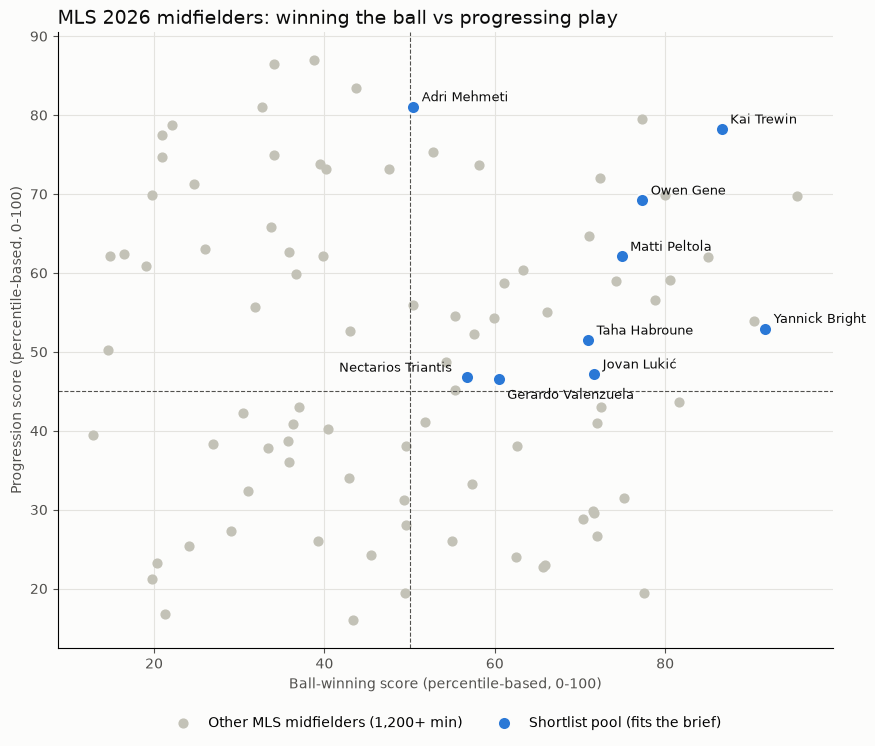

In [17]:
fig, ax = plt.subplots(figsize=(10, 8))
fig.set_facecolor(BACKGROUND)
ax.set_facecolor(BACKGROUND)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(colors=TEXT_MUTED)
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)

others = peer_group[~peer_group["player_name"].isin(pool["player_name"])]

ax.scatter(others["ball_winning_score"], others["progression_score"], s=40, color=PEER_COLOR,
           label=f"Other MLS midfielders ({MIN_MINUTES:,}+ min)")
ax.scatter(pool["ball_winning_score"], pool["progression_score"], s=90, color=POOL_COLOR,
           edgecolor=BACKGROUND, linewidth=1.5, label="Shortlist pool (fits the brief)", zorder=3)

# label offsets for close neighbours
LABEL_OFFSETS = {
    "Nectarios Triantis": (-92, 4),      # label left of the dot
    "Gerardo Valenzuela": (6, -14),       # label below-right of the dot
}
for index, row in pool.iterrows():
    offset = LABEL_OFFSETS.get(row["player_name"], (6, 4))
    ax.annotate(row["player_name"], (row["ball_winning_score"], row["progression_score"]),
                xytext=offset, textcoords="offset points", fontsize=9, color=TEXT_COLOR)

ax.axvline(MIN_BALL_WINNING, color=TEXT_MUTED, linewidth=0.8, linestyle="--")
ax.axhline(MIN_PROGRESSION, color=TEXT_MUTED, linewidth=0.8, linestyle="--")

ax.set_xlabel("Ball-winning score (percentile-based, 0-100)", color=TEXT_MUTED)
ax.set_ylabel("Progression score (percentile-based, 0-100)", color=TEXT_MUTED)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
ax.set_title("MLS 2026 midfielders: winning the ball vs progressing play", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex2_scatter_ballwinning_progression.png", dpi=200, bbox_inches="tight")
plt.show()

## 9 - Save
- Scored peer group
- Pool
- Transfermarkt template CSV (only created if missing, so manual entries are kept)

In [18]:
peer_group.to_parquet(PROCESSED_FOLDER / "ex2_peer_group_scored.parquet")
pool.to_parquet(PROCESSED_FOLDER / "ex2_pool.parquet")

lookup = pool[["player_name", "current_team", "age", "guaranteed_compensation", "score"]].copy()
lookup["age"] = lookup["age"].round(1)
lookup["score"] = lookup["score"].round(1)
lookup["market_value_eur"] = ""          # to fill in from Transfermarkt
lookup["contract_until"] = ""            # to fill in from Transfermarkt
lookup["transfermarkt_checked_on"] = ""
# don't overwrite the Transfermarkt values entered by hand
lookup_file = PROCESSED_FOLDER / "ex2_pool_for_transfermarkt.csv"
if lookup_file.exists():
    print("Template already exists, not overwritten:", lookup_file)
else:
    lookup.to_csv(lookup_file, index=False)
    print("Template created:", lookup_file)
lookup

Template already exists, not overwritten: ../../data/processed/ex2_pool_for_transfermarkt.csv


,player_name,current_team,age,guaranteed_compensation,score,market_value_eur,contract_until,transfermarkt_checked_on
3,Kai Trewin,New York City FC,25.5,311542.0,83.3,,,
457,Yannick Bright,Inter Miami CF,25.2,464192.0,76.2,,,
551,Owen Gene,Minnesota United FC,23.6,450100.0,74.1,,,
574,Matti Peltola,D.C. United,24.4,876000.0,69.8,,,
184,Taha Habroune,Columbus Crew,20.8,152000.0,63.2,,,
295,Adri Mehmeti,New York Red Bulls,17.6,158980.0,62.7,,,
525,Jovan Lukić,Philadelphia Union,24.8,441375.0,61.9,,,
666,Gerardo Valenzuela,FC Cincinnati,22.1,142542.0,54.9,,,
613,Nectarios Triantis,Minnesota United FC,23.5,732665.0,52.7,,,
